# Neural ODEs — Irregular observations and mini-batching for time-dependent dynamics


We progress from autonomous models to a genuinely **non-autonomous** vector field, and compare mini-batching strategies when trajectories start at different absolute times and are measured on irregular grids.

**Goals**
1. Understand the distinction between *observation times*, *solver steps*, and *mini-batch windows*.
2. Construct a realistic collection of noisy, irregularly sampled trajectories with a time-dependent external force.
3. Train a Neural ODE on shared temporal windows using `DataLoader`.
4. Correctly handle windows starting at **different absolute times**, including different relative observation grids.
5. Compare per-window integration, grouping, union-grid batching, and time-rescaling.

Increase epoch counts for more precise fits.

In [1]:
%pip install torchdiffeq

In [2]:
# In Colab/Jupyter, run once if needed:
# %pip install torchdiffeq

import math, time, random
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

try:
    from torchdiffeq import odeint
except ImportError as exc:
    raise ImportError("Install torchdiffeq: run `%pip install torchdiffeq` then restart this cell") from exc

SEED = 14
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
print("Device:", DEVICE)

Device: cpu


## 1. A richer dynamical system: an externally forced oscillator

We observe position and velocity, $z=(x,v)$, evolving according to

$$\dot x=v,\qquad
\dot v=-\omega^2x-\gamma v
+ A\sin(\nu t)+P\exp\!\left(-\frac{(t-t_c)^2}{2\sigma^2}\right).$$

The sinusoidal excitation and temporary pulse depend on **absolute physical time**. Two trajectories with the **same state**, but different clock times, can have different derivatives. Consequently, resetting each training window's time coordinate to zero **without passing its absolute start time** changes the modeled dynamics.

For illustration we integrate a known field to synthesize data. During learning, the neural model does **not** see the true equations, only the observations.

observed: (52, 55, 2) t_shared: (55,)


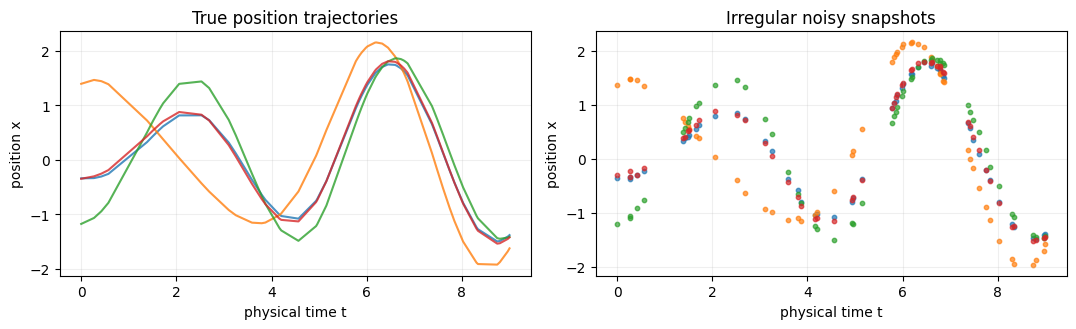

In [3]:
class TrueForcedOscillator(nn.Module):
    def forward(self, t, z):
        x, v = z[..., 0], z[..., 1]
        force = 0.85 * torch.sin(1.6 * t) + 1.1 * torch.exp(-0.5 * ((t - 5.0) / 0.38)**2)
        return torch.stack((v, -1.5 * x - 0.24 * v + force * torch.ones_like(x)), dim=-1)

true_field = TrueForcedOscillator().to(DEVICE)

def make_irregular_times(n, end=9.0, seed=0):
    rng = np.random.default_rng(seed)
    interior = np.sort(rng.uniform(0.0, end, size=n-2))
    return torch.tensor(np.r_[0.0, interior, end], dtype=DTYPE, device=DEVICE)

# All trajectories share an irregular time grid for the first training scenario.
N_TRAJ, N_OBS, T_END = 52, 55, 9.0
t_shared = make_irregular_times(N_OBS, T_END, seed=SEED)
z0_all = torch.randn(N_TRAJ, 2, device=DEVICE) * torch.tensor([1.0, 0.7], device=DEVICE)
with torch.no_grad():
    clean = odeint(true_field, z0_all, t_shared, rtol=1e-6, atol=1e-7).permute(1,0,2)
    observed = clean + 0.025 * torch.randn_like(clean)

print("observed:", tuple(observed.shape), "t_shared:", tuple(t_shared.shape))
fig, axes = plt.subplots(1,2,figsize=(11,3.4))
for i in range(4):
    axes[0].plot(t_shared.cpu(), clean[i,:,0].cpu(), alpha=.8)
    axes[1].scatter(t_shared.cpu(), observed[i,:,0].cpu(), s=10, alpha=.7)
axes[0].set_title("True position trajectories")
axes[1].set_title("Irregular noisy snapshots")
for ax in axes: ax.set(xlabel="physical time t", ylabel="position x"); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

### Three independent concepts

- **Irregular observations:** data are available only at $t_0<t_1<\cdots$; no interpolation to a regular grid is required.
- **Adaptive solver:** `odeint(..., method="dopri5")` may evaluate $f_\theta$ at additional times not included in the observation list.
- **Mini-batching:** choose a subset of trajectories, a subset of contiguous observed snapshots, or both. A single `odeint` call needs a **one-dimensional shared time vector** (but this vector may be irregular).

## 2. Train on shared-index windows from the same irregular grid

A training example is $(i,s)$: select trajectory $i$ and its $L$ consecutive **observed** snapshots indexed by $s,\ldots,s+L-1$. To combine windows in *one ordinary call* to `odeint`, we first sample a common start index $s$ and a batch of trajectory indices.

These batches use **absolute** timestamps `t_shared[s:s+L]`; they do not require the entire trajectory.

In [4]:
class TimeDependentField(nn.Module):
    def __init__(self, hidden=48):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3,hidden), nn.Tanh(),
                                 nn.Linear(hidden,hidden), nn.Tanh(), nn.Linear(hidden,2))
    def forward(self, t, z):
        # Scalar physical time is broadcast over every trajectory in z: [B,2].
        tt = torch.as_tensor(t, dtype=z.dtype, device=z.device)
        if tt.ndim == 1:  # one different absolute time per trajectory
            tt = tt[:, None]
        tt = torch.ones_like(z[..., :1]) * tt
        return self.net(torch.cat([z, tt], dim=-1))

model = TimeDependentField().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
L, BATCH, EPOCHS = 50, 16, 500
train_obs, train_t = observed[:42], t_shared

def shared_window_step(model, data, times, start, trajectory_indices):
    # [B, L, 2] reference -> [L, B, 2] predictions
    y = data[trajectory_indices, start:start+L]
    absolute_t = times[start:start+L]
    pred = odeint(model, y[:,0], absolute_t, method="rk4",
                  options={"step_size":0.075}).permute(1,0,2)
    return (pred - y).square().mean()

loss_history = []
for epoch in range(EPOCHS):
    order = torch.randperm(train_obs.shape[0], device=DEVICE)
    epoch_losses = []
    for idx in order.split(BATCH):
        start = int(torch.randint(0, len(train_t)-L+1, (1,)).item())
        loss = shared_window_step(model, train_obs, train_t, start, idx)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        epoch_losses.append(loss.item())
    loss_history.append(np.mean(epoch_losses))
    if epoch in {0,EPOCHS-1//4, EPOCHS-1//2,3*(EPOCHS-1//4),EPOCHS-1}:
        print(f"epoch {epoch+1:3d}: window-MSE {loss_history[-1]:.5f}")

plt.plot(loss_history); plt.xlabel('epoch'); plt.ylabel('mini-batch training loss');
plt.title('Training on short irregular-time windows'); plt.grid(alpha=.2); plt.show()

epoch   1: window-MSE 2.92970


KeyboardInterrupt: 

### Evaluate on full held-out trajectories

Short-window fit is **not the same** as accurate long-horizon rollout: model error may accumulate, and the inferred state at the start of each training window comes from the observations (teacher forcing at window boundaries). We therefore separately test integrating from the initial state over the entire horizon.

In [ ]:
model.eval()
with torch.no_grad():
    test_idx = 12
    full_pred = odeint(model, observed[test_idx,0], t_shared, method="rk4",
                       options={"step_size":0.075})
plt.figure(figsize=(9,3.4))
plt.scatter(t_shared.cpu(), observed[test_idx,:,0].cpu(), s=15, label='observed position')
plt.plot(t_shared.cpu(), clean[test_idx,:,0].cpu(), label='true trajectory')
plt.plot(t_shared.cpu(), full_pred[:,0].cpu(), label='NODE full rollout')
plt.xlabel('time'); plt.ylabel('position'); plt.legend(); plt.grid(alpha=.2); plt.show()

## 3. Different physical start times: here naive time shifting fails

For an **autonomous** ODE $\dot z=f_\theta(z)$, a window at $t_0$ can be described using relative time $\tau=t-t_0$ without any extra information. For a **non-autonomous** ODE,

$$\frac{dz}{d\tau}=f_\theta(t_0+\tau,z),$$

so the offset $t_0$ must be preserved. A safe vectorized wrapper accepts a **different** $t_{0,b}$ for each batch element while the solver's independent variable is common $\tau$.

In [5]:
class OffsetTimeField(nn.Module):
    """Batch of different start times, all evaluated at common *relative* solver time."""
    def __init__(self, field, starts):
        super().__init__()
        self.field = field
        self.starts = starts  # shape [B], constants for this batch
    def forward(self, tau, z):
        # Generic support: model must accept tensor times for each state.
        absolute_t = self.starts + tau
        return self.field(absolute_t, z)


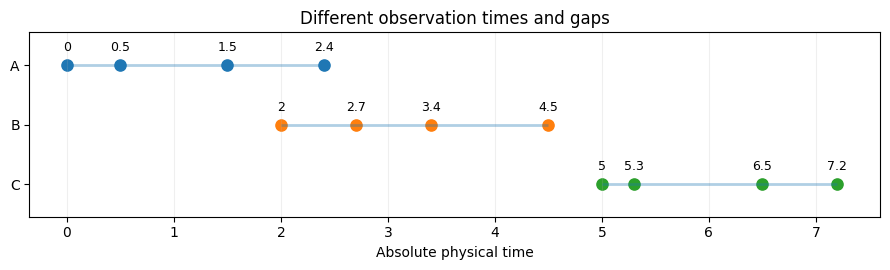

In [6]:
# Figure 1 — Irregular observations on different physical clocks
import matplotlib.pyplot as plt
clocks = [[0, 0.5, 1.5, 2.4], [2, 2.7, 3.4, 4.5], [5, 5.3, 6.5, 7.2]]
fig, ax = plt.subplots(figsize=(9, 2.8))
for i, times in enumerate(clocks):
    y = 2-i
    ax.hlines(y, min(times), max(times), alpha=.35, linewidth=2)
    ax.scatter(times, [y]*len(times), s=65, label=f'Window {chr(65+i)}')
    for t in times:
        ax.annotate(f'{t:g}', (t, y), (0, 10), textcoords='offset points', ha='center', fontsize=9)
ax.set(yticks=[2,1,0], yticklabels=['A','B','C'], xlabel='Absolute physical time', ylim=(-.55,2.55), xlim=(-.35,7.6), title='Different observation times and gaps')
ax.grid(axis='x', alpha=.2)
plt.tight_layout()
plt.show()

## 4. Dataset with distinct, irregular observation grids

Each trajectory has an independent irregular clock (for simplicity all still start at physical time 0). Each `Dataset` item is a contiguous window of observations including its *actual absolute timestamps*.

The `DataLoader` here returns a **Python list** of windows; a standard tensor stack cannot represent arbitrary timestamps/lengths without padding or another batching scheme.

In [7]:
N_INDIVIDUAL = 24
trajectory_records = []
for i in range(N_INDIVIDUAL):
    ti = make_irregular_times(35 + (i % 9), end=9.0, seed=100+i)
    init = torch.randn(2, device=DEVICE) * torch.tensor([0.8,0.6], device=DEVICE)
    with torch.no_grad():
        yi = odeint(true_field, init, ti, rtol=1e-6, atol=1e-7)
        yi = yi + 0.02 * torch.randn_like(yi)
    trajectory_records.append((ti.cpu(), yi.cpu()))

class IrregularWindowDataset(Dataset):
    def __init__(self, records, length=6, stride=3):
        self.records, self.length = records, length
        self.index = [(i,s) for i,(t,y) in enumerate(records)
                      for s in range(0, len(t)-length+1, stride)]
    def __len__(self): return len(self.index)
    def __getitem__(self, idx):
        i,s = self.index[idx]
        t,y = self.records[i]
        return t[s:s+self.length], y[s:s+self.length]

individual_ds = IrregularWindowDataset(trajectory_records[:20], length=6, stride=4)
loader = DataLoader(individual_ds, batch_size=8, shuffle=True,
                    collate_fn=lambda examples: examples)
example_batch = next(iter(loader))
print('number of windows:',len(individual_ds), 'windows in batch:', len(example_batch))
print('first relative time grid:', (example_batch[0][0]-example_batch[0][0][0]).tolist())
print('second relative time grid:', (example_batch[1][0]-example_batch[1][0][0]).tolist())

number of windows: 176 windows in batch: 8
first relative time grid: [0.0, 0.01173543930053711, 0.2387223243713379, 0.31149816513061523, 0.42835474014282227, 0.4655027389526367]
second relative time grid: [0.0, 0.33136892318725586, 1.0090255737304688, 1.0546283721923828, 1.1553478240966797, 1.1985845565795898]


## 5. Strategy A — separate integrations, one optimizer step

The most straightforward and robust approach. Integrate each window on its own absolute time grid. Average losses, call `backward()` **once for the batch**, and then `optimizer.step()` **once**. This *is* mini-batch optimization, even though the ODE solves are not vectorized.

Each window has its own initial observed state. Cost scales roughly with the number of integrations; it is often a good baseline for irregular, heterogeneous datasets.

In [8]:
def loss_separate(field, windows, device=DEVICE):
    losses = []
    for t, y in windows:
        t, y = t.to(device), y.to(device)
        pred = odeint(field, y[0], t, method='rk4', options={'step_size':0.08})
        losses.append((pred-y).square().mean())
    return torch.stack(losses).mean()

model_A = TimeDependentField(hidden=32).to(DEVICE)
opt_A = torch.optim.Adam(model_A.parameters(), lr=2e-3)
for epoch in range(3):  # teaching demo; increase for good results
    losses = []
    for batch in loader:
        loss = loss_separate(model_A, batch)
        opt_A.zero_grad(); loss.backward(); opt_A.step()
        losses.append(loss.item())
    print(f'separate integration, epoch {epoch+1}: {np.mean(losses):.5f}')

separate integration, epoch 1: 1.05724
separate integration, epoch 2: 0.84324
separate integration, epoch 3: 0.62958


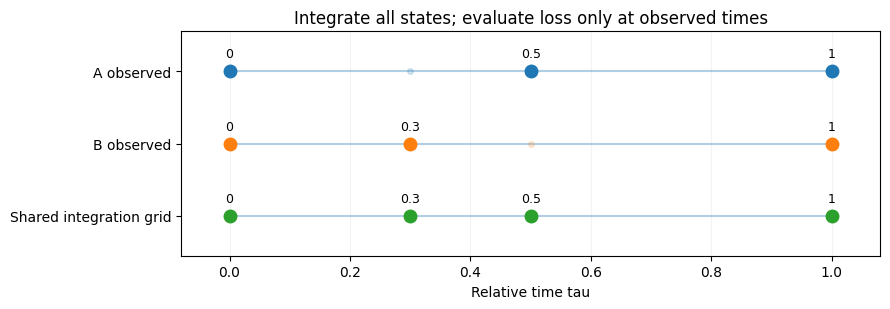

In [9]:
# Figure 2 — Union-grid integration and selective loss evaluation
import matplotlib.pyplot as plt
relative = {'A': [0, 0.5, 1], 'B': [0, 0.3, 1]}
union = sorted(set(relative['A']+relative['B']))
fig, ax = plt.subplots(figsize=(9, 3.2))
for y, name in [(2,'A'),(1,'B'),(0,'Union')]:
    ax.hlines(y, 0, 1, alpha=.35)
    for u in union:
        observed = name=='Union' or u in relative[name]
        ax.plot(u,y,'o', markersize=9 if observed else 4,
                color={'A':'tab:blue','B':'tab:orange','Union':'tab:green'}[name],
                alpha=1 if observed else .18)
        if observed:
            ax.annotate(f'{u:g}', (u,y), (0,10), textcoords='offset points',ha='center',fontsize=9)
ax.set(yticks=[2,1,0], yticklabels=['A observed','B observed','Shared integration grid'], xlabel='Relative time tau',xlim=(-.08,1.08),ylim=(-.55,2.55),title='Integrate all states; evaluate loss only at observed times')
ax.grid(axis='x',alpha=.15)
plt.tight_layout()
plt.show()

## 6. Strategy B — vectorize different offsets and different grids

Let window $b$ start at $s_b$ with observations at relative times $\tau_{b,j}=t_{b,j}-s_b$. Form the **sorted union** $U=\bigcup_{b,j}\{\tau_{b,j}\}$ and integrate every sample on $U$ with

$$\frac{dz_b}{d\tau}=f_\theta(s_b+\tau,z_b).$$

Then gather only the predictions at the original $\tau_{b,j}$ for each sample. This has **one batched integration** and provides exact alignment to the requested observation timestamps (up to numerical solver error). It may become expensive if the union grid is large; adaptive solvers can be more economical than forcing output at a huge union grid.

The following implementation uses `torch.unique(..., return_inverse=True)` so it does **not** compare floating-point timestamps for equality. All windows here have the same number of snapshots, but their times differ. The same idea can be extended to variable lengths with masks.

In [10]:
def loss_union_grid(field, windows, device=DEVICE):
    t_list = [w[0].to(device) for w in windows]
    y_list = [w[1].to(device) for w in windows]
    starts = torch.stack([t[0] for t in t_list])                 # [B]
    rel = torch.stack([t-t[0] for t in t_list])                 # [B,L]
    targets = torch.stack(y_list)                               # [B,L,d]
    initial = targets[:,0,:]                                    # [B,d]
    # Sorted unique union of per-sample relative timestamps.
    union, inverse = torch.unique(rel.reshape(-1), sorted=True, return_inverse=True)
    sample_grid_indices = inverse.reshape(rel.shape)           # [B,L]
    all_predictions = odeint(OffsetTimeField(field, starts), initial, union,
                             method='rk4', options={'step_size':0.08})  # [U,B,d]
    pred = all_predictions[sample_grid_indices, torch.arange(len(windows), device=device)[:,None]]
    return (pred-targets).square().mean()

# Check that it matches the individually integrated predictions, to solver precision.
check_model = TimeDependentField(hidden=32).to(DEVICE)
batch = next(iter(loader))
with torch.no_grad():
    a = loss_separate(check_model, batch)
    b = loss_union_grid(check_model, batch)
print('individual loss:', round(a.item(),7), 'union-grid loss:', round(b.item(),7),
      'difference:', round(abs(a.item()-b.item()),7))

# One gradient step through the batched solver:
opt_B = torch.optim.Adam(check_model.parameters(), lr=2e-3)
loss = loss_union_grid(check_model, batch)
opt_B.zero_grad(); loss.backward(); opt_B.step()
print('One union-grid optimizer step completed.')

individual loss: 1.8552306 union-grid loss: 1.8552321 difference: 1.5e-06
One union-grid optimizer step completed.


### Important subtleties of union-grid batching

1. With a non-autonomous field, `OffsetTimeField` is essential: each sample uses its own $s_b+\tau$.
2. A *single adaptive solver* chooses steps based on the **whole batched state**. Smallest-step demands from a difficult sample may slow down all samples. The two strategies need not have exactly identical numerical errors.
3. The number of output times can approach $B\times L$, even though the physical integration interval is only $[0,\max\tau]$.
4. A single call does **not** imply that the GPU/CPU run will always be faster. Profile for your application.

## 7. Strategy C — group compatible windows

When windows originate from a shared irregular grid, grouping by the same start index makes each group directly batchable. When windows originate from different trajectories but have equal **relative** grids, an offset-aware field suffices. If exact matching is rare, grouping by **duration bins** or **sampling patterns** can improve throughput, but approximate groupings require their actual timestamps to remain intact.

Never replace measured timestamps by approximate common timestamps just to make batches: that changes the supervised problem. For real datasets, grouping plus union-grid-within-group is often an effective compromise.

In [11]:
# Illustration: verify when two relative grids are compatible for one basic odeint call.
grid1 = torch.tensor([2.0,2.3,2.9,3.4])
grid2 = torch.tensor([5.1,5.4,6.0,6.5])
grid3 = torch.tensor([5.1,5.6,6.0,6.5])

def same_relative_grid(a,b):
    return len(a)==len(b) and torch.allclose(a-a[0], b-b[0], atol=1e-6,rtol=0)

print('1 vs 2:', same_relative_grid(grid1,grid2))
print('1 vs 3:', same_relative_grid(grid1,grid3))

1 vs 2: True
1 vs 3: False


## 9. Compare computational costs on the same batch

This is an **illustrative micro-benchmark**, not a universal performance ranking. We also verify gradients flow through both implementations. For comparable timing on GPUs, use `torch.cuda.synchronize()`.

In [12]:
benchmark_batch = next(iter(loader))
bench_model = TimeDependentField(hidden=24).to(DEVICE)

def timed_grad_step(loss_fn, repeats=2):
    timings=[]
    for _ in range(repeats):
        bench_model.zero_grad(set_to_none=True)
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        start=time.perf_counter()
        objective=loss_fn(bench_model,benchmark_batch)
        objective.backward()
        if DEVICE.type=='cuda': torch.cuda.synchronize()
        timings.append(time.perf_counter()-start)
    return np.median(timings)

for name, fn in [('separate solves', loss_separate), ('union grid', loss_union_grid)]:
    print(f'{name:18s}: {timed_grad_step(fn)*1000:.1f} ms/forward+backward')

separate solves   : 158.5 ms/forward+backward
union grid        : 39.7 ms/forward+backward


## 10. Choosing a mini-batching strategy

| Data configuration | Recommended initial approach | Main caveat |
|---|---|---|
| Same observation grid, same indexed window | Batch initial states and call `odeint` once | Use actual (possibly irregular) absolute times |
| Different start times, identical relative grids | Batch with $f_\theta(s_b+\tau,z_b)$ | Never discard $s_b$ for time-dependent systems |
| Different irregular grids | Separate solves, one accumulated mini-batch loss | Many solver calls |
| Different irregular grids, moderate union size | Union of relative times + offset-aware batched field + gather | Union size and adaptive-step coupling |
| Large heterogeneous dataset | Bucket/group similar windows; use union-grid within buckets | Trade-offs between grouping and batching overhead |


**Final remark:** observation irregularity alone does not prohibit mini-batching. The real issues are which solver times can be shared, and whether each trajectory retains its correct **absolute physical time** inside a non-autonomous vector field.